**ML Assignment-2**

**1. Dataset download and understanding.**
The official UCI repository provides the dataset as a CSV file and also supports downloading it through Python's ucimlrepo package.

https://archive.ics.uci.edu/dataset/468/online%2Bshoppers%2Bpurchasing%2Bintention%2Bdataset

In [60]:
pip install ucimlrepo pandas numpy matplotlib seaborn scikit-learn

**2)** **Download the dataset**

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split

# Fetch Online Shoppers Purchasing Intention Dataset
online_shoppers = fetch_ucirepo(id=468)

# Separate independent variables and target variable
X = online_shoppers.data.features
y = online_shoppers.data.targets

# Combine features and target into one DataFrame
df = pd.concat([X, y], axis=1)

# Display first five records
print("First five records:")
display(df.head())

# Display dataset dimensions
print("\nDataset shape:", df.shape)

First five records:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False



Dataset shape: (12330, 18)


**Step 1.2 – Understand the dataset structure**
Before building a model, we need to understand the data.

Concept: Independent and dependent variables

In machine learning:
- Independent variables (X): Input features used to make predictions.
- Dependent variable (y): Output we want the model to predict.

For our project:

X = {17 input features}

y = Revenue

**3) Dataset information**

In [62]:
# Display column names
print("Column Names:")
print(df.columns.tolist())

# Display data types and non-null counts
print("\nDataset Information:")
df.info()

# Display statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all").T)

Column Names:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues        

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


Important observation: All columns have 12,330 non-null values.

This means there are no missing values according to the df.info() output.

However, we still need to check duplicate records separately.

Notice something interesting:
- Average product pages visited = approximately 32.
- Median product pages visited = 18.
- Average time spent = approximately 1,195 seconds.
- Median time spent = approximately 599 seconds.
The mean is considerably higher than the median.

What does this indicate?

Some visitors browse significantly more product pages or spend much longer on the website than the majority of visitors.

This suggests a positively skewed distribution.

**Step 1.3 – Check data quality**
We need to understand whether the dataset has missing values, duplicate records or unexpected data types.

Concept: Missing values

Missing values occur when a particular observation does not have a recorded value for a feature.

For example, if a customer's visitor type is unavailable, that field may contain a missing value.

**4) Data quality checks**

In [63]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Total missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

Missing values:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

Total missing values: 0

Duplicate records: 125

Data types:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
Op

**Step 1.4 – Understand the target variable**

his is particularly important for our classification problem.

**Concept**: Class distribution

***Our target variable is Revenue.***

It has two possible outcomes:
- True: Customer completed a purchase.
- False: Customer did not complete a purchase.

**5) Target distribution**

In [64]:
# Count each target class
print("Revenue Distribution:")
print(df["Revenue"].value_counts())

# Calculate percentage distribution
print("\nRevenue Percentage:")
print(
    df["Revenue"].value_counts(normalize=True) * 100
)

Revenue Distribution:
Revenue
False    10422
True      1908
Name: count, dtype: int64

Revenue Percentage:
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


**6) Inspect duplicate records**

In [65]:
# Extract duplicate records
duplicate_records = df[df.duplicated(keep=False)]

print("Total rows involved in duplicates:",
      len(duplicate_records))

# Display sample duplicate records
display(duplicate_records.head(10))

# Check Revenue distribution among duplicate records
print("\nRevenue distribution in duplicate records:")
print(duplicate_records["Revenue"].value_counts())

Total rows involved in duplicates: 201


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
252,0,0.0,0,0.0,2,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,False,False
286,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,False
293,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
298,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,8,1,Returning_Visitor,False,False
330,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,3,2,3,1,Returning_Visitor,False,False



Revenue distribution in duplicate records:
Revenue
False    201
Name: count, dtype: int64


**7) Create a cleaned dataset**

In [66]:
# Preserve original dataset
df_original = df.copy()

# Remove exact duplicate records
df_cleaned = df.drop_duplicates().copy()

print("Original dataset shape:", df_original.shape)
print("Cleaned dataset shape:", df_cleaned.shape)

print("Records removed:",
      len(df_original) - len(df_cleaned))

Original dataset shape: (12330, 18)
Cleaned dataset shape: (12205, 18)
Records removed: 125


**8) Visualize Purchase Distribution**

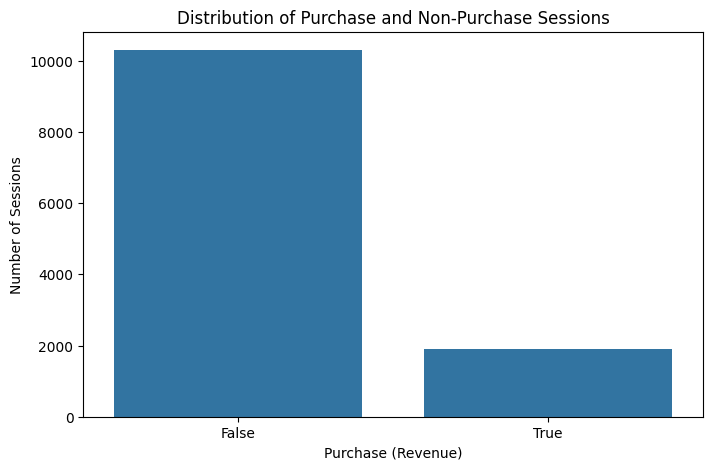

Revenue distribution:
Revenue
False    10297
True      1908
Name: count, dtype: int64

Percentage distribution:
Revenue
False    84.37
True     15.63
Name: proportion, dtype: float64


In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate target distribution
revenue_counts = df_cleaned["Revenue"].value_counts()

# Plot
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_cleaned,
    x="Revenue"
)

plt.title("Distribution of Purchase and Non-Purchase Sessions")
plt.xlabel("Purchase (Revenue)")
plt.ylabel("Number of Sessions")

plt.show()

# Display percentages
print("Revenue distribution:")
print(revenue_counts)

print("\nPercentage distribution:")
print(
    (df_cleaned["Revenue"].value_counts(normalize=True) * 100).round(2)
)

**9) Target distribution after duplicate removal**

In [68]:
print("Cleaned dataset shape:", df_cleaned.shape)

print("\nRevenue distribution:")
print(df_cleaned["Revenue"].value_counts())

print("\nRevenue percentage:")
print(
    (df_cleaned["Revenue"].value_counts(normalize=True) * 100).round(2)
)

Cleaned dataset shape: (12205, 18)

Revenue distribution:
Revenue
False    10297
True      1908
Name: count, dtype: int64

Revenue percentage:
Revenue
False    84.37
True     15.63
Name: proportion, dtype: float64


**10) Compare browsing duration**

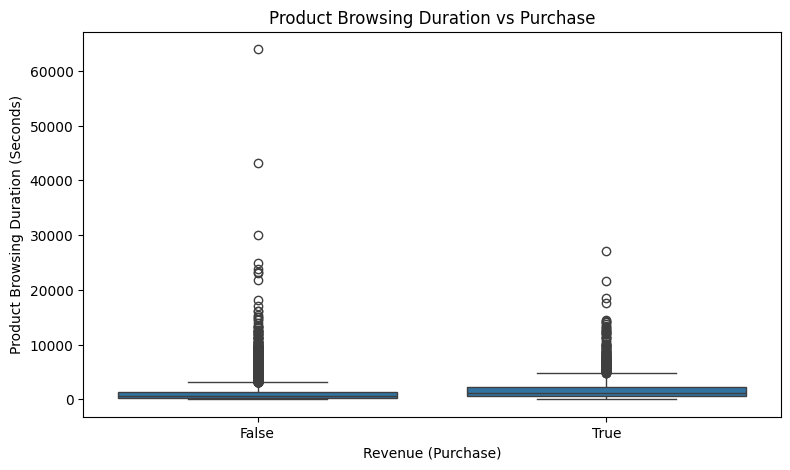

In [69]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_cleaned,
    x="Revenue",
    y="ProductRelated_Duration"
)

plt.title("Product Browsing Duration vs Purchase")
plt.xlabel("Revenue (Purchase)")
plt.ylabel("Product Browsing Duration (Seconds)")

plt.show()

**11) Log-scale comparison**

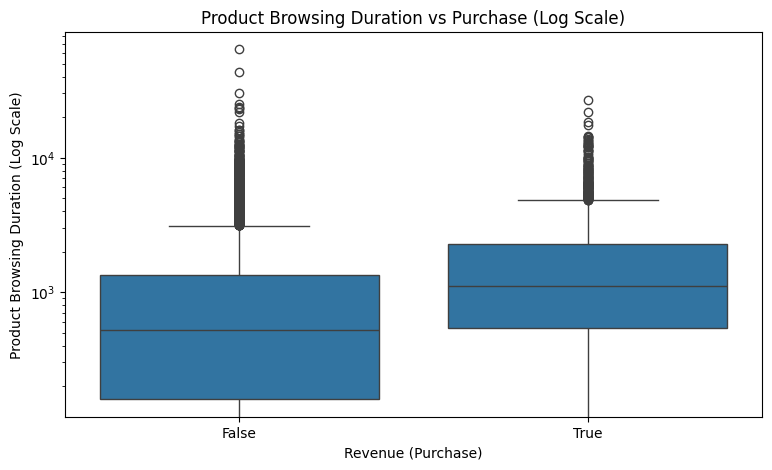

In [70]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_cleaned,
    x="Revenue",
    y="ProductRelated_Duration"
)

plt.yscale("log")

plt.title("Product Browsing Duration vs Purchase (Log Scale)")
plt.xlabel("Revenue (Purchase)")
plt.ylabel("Product Browsing Duration (Log Scale)")

plt.show()

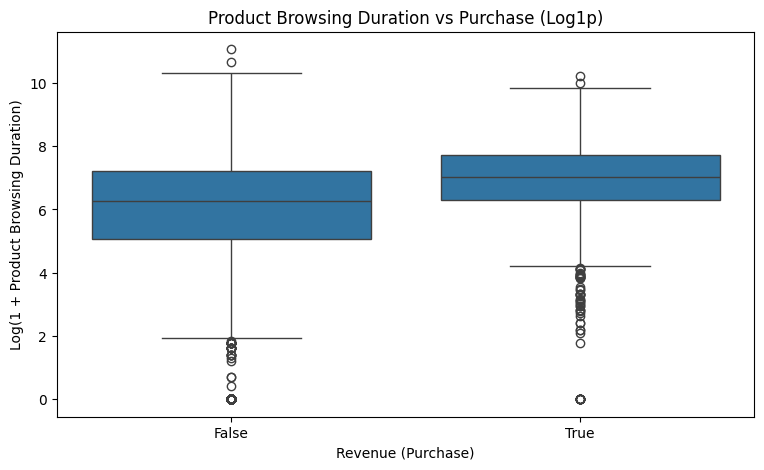

In [71]:
# Apply log1p transformation
df_cleaned["Log_ProductRelated_Duration"] = np.log1p(
    df_cleaned["ProductRelated_Duration"]
)

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_cleaned,
    x="Revenue",
    y="Log_ProductRelated_Duration"
)

plt.title("Product Browsing Duration vs Purchase (Log1p)")
plt.xlabel("Revenue (Purchase)")
plt.ylabel("Log(1 + Product Browsing Duration)")
plt.show()

**VisitorType versus Revenue**

In [72]:
# Calculate purchase counts by visitor type
visitor_revenue = pd.crosstab(
    df_cleaned["VisitorType"],
    df_cleaned["Revenue"]
)

print("Visitor Type vs Revenue:")
display(visitor_revenue)

# Calculate purchase percentage within each visitor type
visitor_purchase_rate = (
    pd.crosstab(
        df_cleaned["VisitorType"],
        df_cleaned["Revenue"],
        normalize="index"
    ) * 100
)

print("\nPurchase percentage by visitor type:")
display(visitor_purchase_rate.round(2))

Visitor Type vs Revenue:


Revenue,False,True
VisitorType,,
New_Visitor,1271,422
Other,65,16
Returning_Visitor,8961,1470



Purchase percentage by visitor type:


Revenue,False,True
VisitorType,,
New_Visitor,75.07,24.93
Other,80.25,19.75
Returning_Visitor,85.91,14.09


**Monthly purchase patterns**

In [73]:
# Calculate purchase counts by month
monthly_revenue = pd.crosstab(
    df_cleaned["Month"],
    df_cleaned["Revenue"]
)

print("Monthly Revenue Distribution:")
display(monthly_revenue)

# Calculate purchase percentage within each month
monthly_purchase_rate = (
    pd.crosstab(
        df_cleaned["Month"],
        df_cleaned["Revenue"],
        normalize="index"
    ) * 100
)

print("\nMonthly Purchase Rate (%):")
display(monthly_purchase_rate.round(2))

Monthly Revenue Distribution:


Revenue,False,True
Month,,
Aug,357,76
Dec,1490,216
Feb,178,3
Jul,366,66
June,256,29
Mar,1668,192
May,2964,365
Nov,2222,760
Oct,434,115



Monthly Purchase Rate (%):


Revenue,False,True
Month,,
Aug,82.45,17.55
Dec,87.34,12.66
Feb,98.34,1.66
Jul,84.72,15.28
June,89.82,10.18
Mar,89.68,10.32
May,89.04,10.96
Nov,74.51,25.49
Oct,79.05,20.95


**Correlation analysis**

Business/ML question: Are some numerical features strongly correlated with each other? If so, could they contain overlapping information?

This is particularly useful before building Logistic Regression and other classifiers.

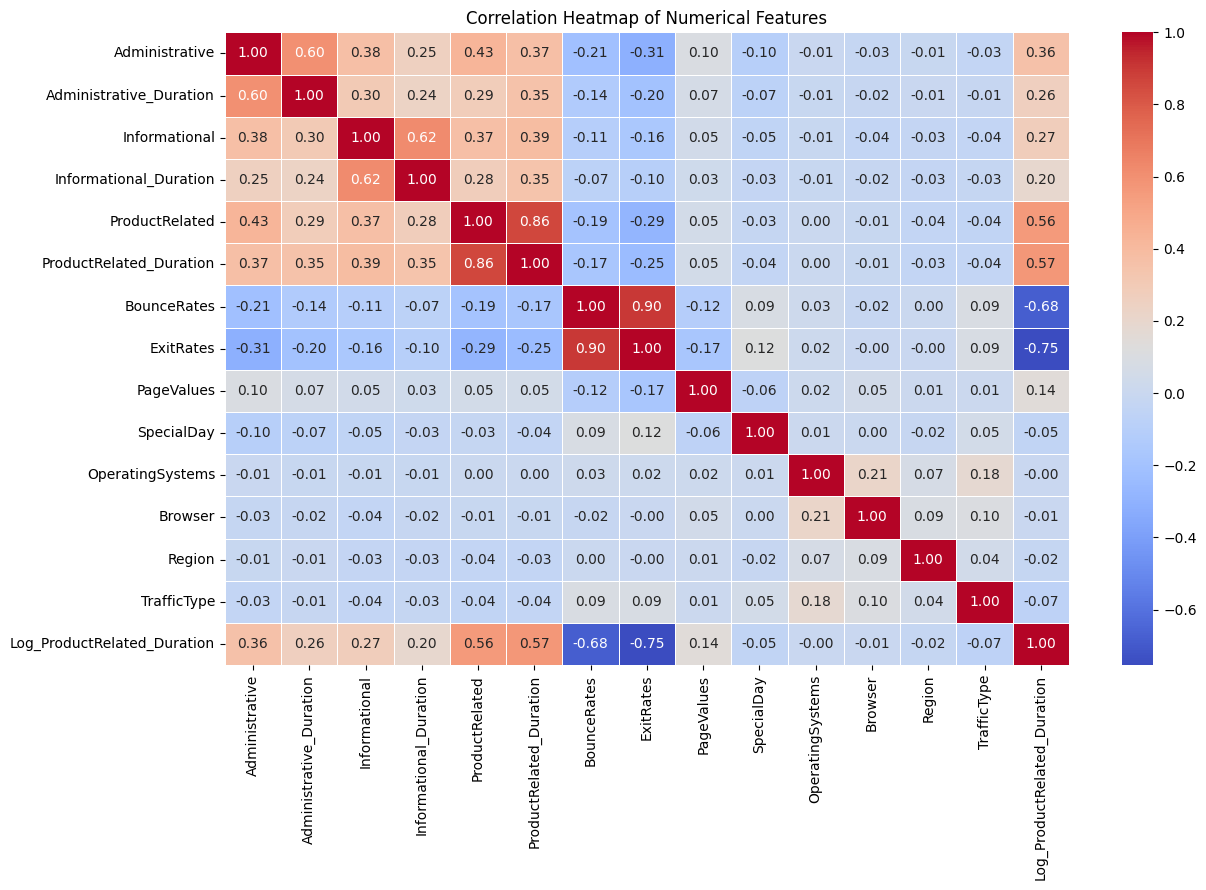

In [74]:
# Select numerical columns
numerical_features = df_cleaned.select_dtypes(
    include=["int64", "float64"]
)

# Calculate correlation matrix
correlation_matrix = numerical_features.corr()

# Visualize correlation matrix
plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

**Correlation with Revenue**

In [75]:
# Create a copy for correlation analysis
correlation_df = df_cleaned.copy()

# Convert Boolean target into numeric values
# False = 0, True = 1
correlation_df["Revenue_numeric"] = (
    correlation_df["Revenue"].astype(int)
)

# Exclude the log-transformed helper column
# Also exclude integer-coded categorical identifiers
exclude_columns = [
    "Log_ProductRelated_Duration",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

correlation_features = correlation_df.drop(
    columns=exclude_columns,
    errors="ignore"
)

# Select numerical columns
correlation_features = correlation_features.select_dtypes(
    include=["int64", "float64"]
)

# Calculate correlation with Revenue
revenue_correlation = (
    correlation_features.corr()["Revenue_numeric"]
    .drop("Revenue_numeric")
    .sort_values(ascending=False)
)

print("Correlation of numerical features with Revenue:")
display(revenue_correlation.to_frame("Correlation"))

Correlation of numerical features with Revenue:


,Correlation
PageValues,0.491894
ProductRelated,0.156042
ProductRelated_Duration,0.150077
Administrative,0.136330
Informational,0.093626
Administrative_Duration,0.091768
Informational_Duration,0.069358
SpecialDay,-0.083601
BounceRates,-0.145091
ExitRates,-0.204320


**Page Value Group Vs Revenue**

In [76]:
# Divide sessions into zero and non-zero PageValues groups
df_cleaned["PageValues_Group"] = np.where(
    df_cleaned["PageValues"] == 0,
    "Zero PageValues",
    "Positive PageValues"
)

# Count purchase outcomes
pagevalues_counts = pd.crosstab(
    df_cleaned["PageValues_Group"],
    df_cleaned["Revenue"]
)

print("PageValues group vs Revenue:")
display(pagevalues_counts)

# Calculate purchase rate within each group
pagevalues_purchase_rate = (
    pd.crosstab(
        df_cleaned["PageValues_Group"],
        df_cleaned["Revenue"],
        normalize="index"
    ) * 100
)

print("\nPurchase rate by PageValues group:")
display(pagevalues_purchase_rate.round(2))

PageValues group vs Revenue:


Revenue,False,True
PageValues_Group,,
Positive PageValues,1192,1538
Zero PageValues,9105,370



Purchase rate by PageValues group:


Revenue,False,True
PageValues_Group,,
Positive PageValues,43.66,56.34
Zero PageValues,96.09,3.91


In [77]:
# Count purchase outcomes by weekend
weekend_revenue = pd.crosstab(
    df_cleaned["Weekend"],
    df_cleaned["Revenue"]
)

print("Weekend vs Revenue:")
display(weekend_revenue)

# Calculate purchase rate for each group
weekend_purchase_rate = (
    pd.crosstab(
        df_cleaned["Weekend"],
        df_cleaned["Revenue"],
        normalize="index"
    ) * 100
)

print("\nPurchase percentage by Weekend:")
display(weekend_purchase_rate.round(2))

Weekend vs Revenue:


Revenue,False,True
Weekend,,
False,7937,1409
True,2360,499



Purchase percentage by Weekend:


Revenue,False,True
Weekend,,
False,84.92,15.08
True,82.55,17.45


In [78]:
# Categorical features to analyse
categorical_features = [
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

for feature in categorical_features:

    print("\n" + "=" * 60)
    print(f"Purchase analysis for {feature}")
    print("=" * 60)

    # Count of purchase outcomes
    counts = pd.crosstab(
        df_cleaned[feature],
        df_cleaned["Revenue"]
    )

    print("\nPurchase counts:")
    display(counts)

    # Purchase rate within each category
    rates = (
        pd.crosstab(
            df_cleaned[feature],
            df_cleaned["Revenue"],
            normalize="index"
        ) * 100
    )

    print("\nPurchase percentages:")
    display(rates.round(2))


Purchase analysis for OperatingSystems

Purchase counts:


Revenue,False,True
OperatingSystems,,
1,2170,379
2,5386,1155
3,2262,268
4,393,85
5,5,1
6,17,2
7,6,1
8,58,17



Purchase percentages:


Revenue,False,True
OperatingSystems,,
1,85.13,14.87
2,82.34,17.66
3,89.41,10.59
4,82.22,17.78
5,83.33,16.67
6,89.47,10.53
7,85.71,14.29
8,77.33,22.67



Purchase analysis for Browser

Purchase counts:


Revenue,False,True
Browser,,
1,2062,365
2,6660,1223
3,100,5
4,601,130
5,379,86
6,154,20
7,43,6
8,114,21
9,1,0


... (6 outputs left out)


Purchase analysis for TrafficType

Purchase counts:


Revenue,False,True
TrafficType,,
1,2126,262
2,3064,847
3,1833,180
4,901,165
5,204,56
6,390,53
7,28,12
8,248,95
9,37,4



Purchase percentages:


Revenue,False,True
TrafficType,,
1,89.03,10.97
2,78.34,21.66
3,91.06,8.94
4,84.52,15.48
5,78.46,21.54
6,88.04,11.96
7,70.00,30.00
8,72.30,27.70
9,90.24,9.76


**EDA completion: What have we learned?**

Our EDA findings
1. Target distribution
   
   84.37% non-purchasing sessions and 15.63% purchasing sessions. The dataset is imbalanced.
2. Product browsing duration
   
   Purchasing sessions generally have longer product browsing durations.
3. Visitor type
   
   New Visitors have a higher purchase rate (24.93%) than Returning Visitors (14.09%).
4. Monthly patterns
   
   November has the highest purchase rate (25.49%), while February has the lowest (1.66%).
5. Weekend
   
   Weekend sessions have a slightly higher purchase rate (17.45%) than weekdays (15.08%).
6. Correlation
   
   BounceRates and ExitRates are strongly correlated (0.90). ProductRelated and ProductRelated_Duration are also strongly correlated (0.86).
7. PageValues
   
   Positive PageValues sessions have a 56.34% purchase rate, compared with 3.91% for zero PageValues sessions. We need to investigate prediction-time availability and possible leakage.
8. TrafficType
   
   Purchase rates differ considerably across traffic categories.

**Next major phase: Data preprocessing**

**Identify feature types**

In [79]:
numerical_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

In [80]:
categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType"
]

In [81]:
binary_features = ["Weekend"]

**Prepare X and y**

In [82]:
# Define input features
feature_columns = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay",
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

# Create X (input features)
X = df_cleaned[feature_columns].copy()

# Create y (target variable)
y = df_cleaned["Revenue"].astype(int)

# Display dimensions
print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Input feature shape: (12205, 17)
Target shape: (12205,)

Input features:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

Target distribution:
Revenue
0    10297
1     1908
Name: count, dtype: int64


**Split the dataset**

In [83]:
from sklearn.model_selection import train_test_split

# Convert the binary Weekend feature from Boolean to integer
X["Weekend"] = X["Weekend"].astype(int)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the dimensions
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training feature shape: (9764, 17)
Testing feature shape: (2441, 17)

Training target distribution:
Revenue
0    8238
1    1526
Name: count, dtype: int64

Testing target distribution:
Revenue
0    2059
1     382
Name: count, dtype: int64


**Define the preprocessing pipeline**

In [84]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# 1. Numerical features
numerical_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

# 2. Categorical features
categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType"
]

# 3. Binary feature
binary_features = ["Weekend"]

# Define transformations for each feature group
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_features),
        ("bin", "passthrough", binary_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline defined successfully!")

Preprocessing pipeline defined successfully!


**Classifier 1: Train the Logistic Regression model**

In [85]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression pipeline
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


**Evaluate Logistic Regression**

In [86]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Generate predictions
y_pred = logistic_model.predict(X_test)

# Generate purchase probabilities
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
logistic_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred),
    "AUC": roc_auc_score(y_test, y_prob),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "MCC": matthews_corrcoef(y_test, y_pred)
}

# Display metrics
print("Logistic Regression - Evaluation Metrics")
print("=" * 50)

for metric, value in logistic_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Display classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Purchase", "Purchase"],
    zero_division=0
))

Logistic Regression - Evaluation Metrics
Accuracy: 0.8873
AUC: 0.8998
Precision: 0.7536
Recall: 0.4162
F1: 0.5363
MCC: 0.5055

Confusion Matrix:
[[2007   52]
 [ 223  159]]

Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.90      0.97      0.94      2059
    Purchase       0.75      0.42      0.54       382

    accuracy                           0.89      2441
   macro avg       0.83      0.70      0.74      2441
weighted avg       0.88      0.89      0.87      2441



**Classifier 2: Decision Tree**

In [87]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree pipeline
decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=8,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


**Evaluate the Decision Tree**

In [88]:
# Generate predictions
dt_pred = decision_tree_model.predict(X_test)

# Generate purchase probabilities
dt_prob = decision_tree_model.predict_proba(X_test)[:, 1]

# Calculate metrics
decision_tree_results = {
    "Model": "Decision Tree",
    "Accuracy": accuracy_score(y_test, dt_pred),
    "AUC": roc_auc_score(y_test, dt_prob),
    "Precision": precision_score(y_test, dt_pred, zero_division=0),
    "Recall": recall_score(y_test, dt_pred, zero_division=0),
    "F1": f1_score(y_test, dt_pred, zero_division=0),
    "MCC": matthews_corrcoef(y_test, dt_pred)
}

# Display metrics
print("Decision Tree - Evaluation Metrics")
print("=" * 50)

for metric, value in decision_tree_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_pred,
    target_names=["No Purchase", "Purchase"],
    zero_division=0
))

Decision Tree - Evaluation Metrics
Accuracy: 0.8914
AUC: 0.8808
Precision: 0.6667
Recall: 0.6126
F1: 0.6385
MCC: 0.5754

Confusion Matrix:
[[1942  117]
 [ 148  234]]

Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.93      0.94      0.94      2059
    Purchase       0.67      0.61      0.64       382

    accuracy                           0.89      2441
   macro avg       0.80      0.78      0.79      2441
weighted avg       0.89      0.89      0.89      2441



**Classifier 3: K-Nearest Neighbors (KNN)**

**Train the KNN model**

In [89]:
from sklearn.neighbors import KNeighborsClassifier

# Create KNN pipeline
knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        weights="uniform",
        metric="minkowski",
        p=2
    ))
])

# Train the model
knn_model.fit(X_train, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


**Evaluate the KNN model**

In [90]:
# Generate predictions
knn_pred = knn_model.predict(X_test)

# Generate purchase probabilities
knn_prob = knn_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
knn_results = {
    "Model": "K-Nearest Neighbors",
    "Accuracy": accuracy_score(y_test, knn_pred),
    "AUC": roc_auc_score(y_test, knn_prob),
    "Precision": precision_score(y_test, knn_pred, zero_division=0),
    "Recall": recall_score(y_test, knn_pred, zero_division=0),
    "F1": f1_score(y_test, knn_pred, zero_division=0),
    "MCC": matthews_corrcoef(y_test, knn_pred)
}

# Display metrics
print("KNN - Evaluation Metrics")
print("=" * 50)

for metric, value in knn_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, knn_pred))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    knn_pred,
    target_names=["No Purchase", "Purchase"],
    zero_division=0
))

KNN - Evaluation Metrics
Accuracy: 0.8742
AUC: 0.8002
Precision: 0.6682
Recall: 0.3901
F1: 0.4926
MCC: 0.4465

Confusion Matrix:
[[1985   74]
 [ 233  149]]

Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.89      0.96      0.93      2059
    Purchase       0.67      0.39      0.49       382

    accuracy                           0.87      2441
   macro avg       0.78      0.68      0.71      2441
weighted avg       0.86      0.87      0.86      2441



**Classifier 4: Naive Bayes**

We'll use Gaussian Naive Bayes because our dataset contains continuous numerical features, along with one-hot encoded categorical features and a binary feature.

Gaussian Naive Bayes assumes that each continuous feature follows a Gaussian (normal) distribution within each class.

In [91]:
from sklearn.naive_bayes import GaussianNB

# Create Gaussian Naive Bayes pipeline
naive_bayes_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GaussianNB())
])

# Train the model
naive_bayes_model.fit(X_train, y_train)

print("Gaussian Naive Bayes model trained successfully!")

Gaussian Naive Bayes model trained successfully!


**Evaluate the Naive Bayes model**

In [92]:
# Generate predictions
nb_pred = naive_bayes_model.predict(X_test)

# Generate purchase probabilities
nb_prob = naive_bayes_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
naive_bayes_results = {
    "Model": "Gaussian Naive Bayes",
    "Accuracy": accuracy_score(y_test, nb_pred),
    "AUC": roc_auc_score(y_test, nb_prob),
    "Precision": precision_score(y_test, nb_pred, zero_division=0),
    "Recall": recall_score(y_test, nb_pred, zero_division=0),
    "F1": f1_score(y_test, nb_pred, zero_division=0),
    "MCC": matthews_corrcoef(y_test, nb_pred)
}

# Display metrics
print("Gaussian Naive Bayes - Evaluation Metrics")
print("=" * 50)

for metric, value in naive_bayes_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, nb_pred))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    nb_pred,
    target_names=["No Purchase", "Purchase"],
    zero_division=0
))

Gaussian Naive Bayes - Evaluation Metrics
Accuracy: 0.2773
AUC: 0.7508
Precision: 0.1756
Recall: 0.9791
F1: 0.2978
MCC: 0.1375

Confusion Matrix:
[[ 303 1756]
 [   8  374]]

Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.97      0.15      0.26      2059
    Purchase       0.18      0.98      0.30       382

    accuracy                           0.28      2441
   macro avg       0.57      0.56      0.28      2441
weighted avg       0.85      0.28      0.26      2441



**Train the SVM model**

In [93]:
from sklearn.svm import SVC

# Create SVM pipeline
svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=42
    ))
])

# Train the model
svm_model.fit(X_train, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


**Evaluate the SVM model**

In [94]:
# Generate predictions
svm_pred = svm_model.predict(X_test)

# Generate decision scores for AUC
svm_scores = svm_model.decision_function(X_test)

# Calculate evaluation metrics
svm_results = {
    "Model": "Support Vector Machine",
    "Accuracy": accuracy_score(y_test, svm_pred),
    "AUC": roc_auc_score(y_test, svm_scores),
    "Precision": precision_score(y_test, svm_pred, zero_division=0),
    "Recall": recall_score(y_test, svm_pred, zero_division=0),
    "F1": f1_score(y_test, svm_pred, zero_division=0),
    "MCC": matthews_corrcoef(y_test, svm_pred)
}

# Display metrics
print("SVM - Evaluation Metrics")
print("=" * 50)

for metric, value in svm_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_pred))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    svm_pred,
    target_names=["No Purchase", "Purchase"],
    zero_division=0
))

SVM - Evaluation Metrics
Accuracy: 0.8955
AUC: 0.8738
Precision: 0.7378
Recall: 0.5157
F1: 0.6071
MCC: 0.5607

Confusion Matrix:
[[1989   70]
 [ 185  197]]

Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.91      0.97      0.94      2059
    Purchase       0.74      0.52      0.61       382

    accuracy                           0.90      2441
   macro avg       0.83      0.74      0.77      2441
weighted avg       0.89      0.90      0.89      2441



**Create the comparison DataFrame**

In [95]:
import pandas as pd

# Collect results from all five classifiers
all_results = [
    logistic_results,
    decision_tree_results,
    knn_results,
    naive_bayes_results,
    svm_results
]

# Create comparison DataFrame
comparison_df = pd.DataFrame(all_results)

# Set model name as the index
comparison_df.set_index("Model", inplace=True)

# Display results
print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 70)

print(comparison_df.round(4))

# Identify the best model for each metric
print("\nBEST MODEL FOR EACH METRIC")
print("=" * 70)

for metric in comparison_df.columns:
    best_model = comparison_df[metric].idxmax()
    best_score = comparison_df[metric].max()

    print(f"{metric}: {best_model} ({best_score:.4f})")

FINAL MODEL PERFORMANCE COMPARISON
                        Accuracy     AUC  Precision  Recall      F1     MCC
Model                                                                      
Logistic Regression       0.8873  0.8998     0.7536  0.4162  0.5363  0.5055
Decision Tree             0.8914  0.8808     0.6667  0.6126  0.6385  0.5754
K-Nearest Neighbors       0.8742  0.8002     0.6682  0.3901  0.4926  0.4465
Gaussian Naive Bayes      0.2773  0.7508     0.1756  0.9791  0.2978  0.1375
Support Vector Machine    0.8955  0.8738     0.7378  0.5157  0.6071  0.5607

BEST MODEL FOR EACH METRIC
Accuracy: Support Vector Machine (0.8955)
AUC: Logistic Regression (0.8998)
Precision: Logistic Regression (0.7536)
Recall: Gaussian Naive Bayes (0.9791)
F1: Decision Tree (0.6385)
MCC: Decision Tree (0.5754)


**Which model should we consider the overall winner?**
I would select Decision Tree as the best balanced baseline for this dataset.

Why?
- It has the highest F1 score, meaning it provides the best balance between precision and recall among these five models.
- It has the highest MCC, which is particularly useful when evaluating classification performance on an imbalanced dataset.
- Its recall of 0.6126 means it identifies 234 of the 382 actual purchasing sessions in the test set.
SVM has the highest accuracy, but accuracy alone does not tell us how effectively the model identifies purchasing sessions.

**Recommended next experiment: investigate PageValues**

Before finalising the models, Let's do one additional experiment.

Earlier, we found that PageValues has a relatively strong relationship with the target:
- Sessions with positive PageValues: purchase rate approximately 56.34%.
- Sessions with zero PageValues: purchase rate approximately 3.91%.
This feature may be highly informative. However, we should check whether it is genuinely available at the time we intend to make a prediction.

For example:
- If we predict purchase intention after the browsing session, PageValues may be a legitimate feature.
- If we predict purchase intention early in the session, it may contain information that would not yet be available.
Let's compare the models with and without PageValues. This is a sensitivity experiment, not proof that the feature causes data leakage.

**Prepare data without PageValues**

In [96]:
# Remove PageValues from the existing train and test datasets
X_train_no_pv = X_train.drop(columns=["PageValues"])
X_test_no_pv = X_test.drop(columns=["PageValues"])

# Updated numerical features
numerical_features_no_pv = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "SpecialDay"
]

# Categorical and binary features remain unchanged
categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType"
]

binary_features = ["Weekend"]

# Create updated preprocessing pipeline
preprocessor_no_pv = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features_no_pv),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_features),
        ("bin", "passthrough", binary_features)
    ],
    remainder="drop"
)

print("Training shape:", X_train_no_pv.shape)
print("Testing shape:", X_test_no_pv.shape)

Training shape: (9764, 16)
Testing shape: (2441, 16)


**Evaluate all five models without PageValues**

In [97]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

models_no_pv = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        criterion="gini",
        max_depth=8,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5,
        weights="uniform",
        metric="minkowski",
        p=2
    ),

    "Gaussian Naive Bayes": GaussianNB(),

    "Support Vector Machine": SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=42
    )
}

no_pv_results = []

for model_name, classifier in models_no_pv.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor_no_pv),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train_no_pv, y_train)

    predictions = pipeline.predict(X_test_no_pv)

    # Obtain scores for ROC-AUC
    if hasattr(pipeline, "predict_proba"):
        scores = pipeline.predict_proba(X_test_no_pv)[:, 1]
    else:
        scores = pipeline.decision_function(X_test_no_pv)

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "AUC": roc_auc_score(y_test, scores),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_test, predictions)
    }

    no_pv_results.append(results)

comparison_no_pv = pd.DataFrame(no_pv_results)
comparison_no_pv.set_index("Model", inplace=True)

print("MODEL PERFORMANCE WITHOUT PAGEVALUES")
print("=" * 75)
print(comparison_no_pv.round(4))

MODEL PERFORMANCE WITHOUT PAGEVALUES
                        Accuracy     AUC  Precision  Recall      F1     MCC
Model                                                                      
Logistic Regression       0.8435  0.7539     0.5000  0.0393  0.0728  0.1055
Decision Tree             0.8324  0.7347     0.4172  0.1780  0.2495  0.1919
K-Nearest Neighbors       0.8247  0.6533     0.3544  0.1466  0.2074  0.1433
Gaussian Naive Bayes      0.2716  0.6935     0.1744  0.9791  0.2961  0.1327
Support Vector Machine    0.8435  0.6829     0.5000  0.0026  0.0052  0.0271


**Compare performance with and without PageValues**

These results are very informative. Removing PageValues causes a substantial drop in performance across all five classifiers, especially in their ability to identify purchasing sessions.

This confirms that PageValues is an extremely influential feature in this dataset. It does not, by itself, prove that the feature is data leakage.

The most striking result is Logistic Regression:
- With PageValues, recall is 41.62%.
- Without PageValues, recall is only 3.93%.
Similarly, Decision Tree recall drops from 61.26% to 17.80%.

This tells us that PageValues provides substantial information that helps distinguish purchasing sessions from non-purchasing sessions.

**An important detail from the UCI dataset documentation**

The UCI description defines PageValues as the average value associated with a web page visited before completing an e-commerce transaction. It is a Google Analytics metric.


This definition makes the feature worth investigating carefully.

It may encode information closely connected to the eventual purchase outcome. Whether that is leakage depends on how and when the value is calculated and whether it is available at your intended prediction point.

**My recommendation for this assignment:**

I recommend retaining both experiments in analysis:
1. Primary experiment: All 17 features, including PageValues.
2. Sensitivity experiment: 16 features, excluding PageValues.

***For the primary experiment***, Decision Tree remains our best balanced baseline with F1 = 0.6385 and MCC = 0.5754.

*This describesan investigation of the influence of a highly predictive feature.*

**Hyperparameter tuning**

Before tuning, we make one improvement to the evaluation process: use cross-validation on the training data and consider class imbalance when selecting model settings.

We should:
- Tune Decision Tree, Logistic Regression and SVM first.
- Evaluate candidate models using F1 or MCC, not accuracy alone.
- Keep the test set untouched until final evaluation.
- Consider threshold tuning after model selection.

**Decision tree Hyperparameter Tuning**

In [98]:
DecisionTreeClassifier(
    criterion="gini",
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, min_samples_split=10,
                       random_state=42)

**Run GridSearchCV**

In [99]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Build a pipeline so preprocessing is fitted separately
# inside each cross-validation training fold.
dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Hyperparameter combinations to evaluate
param_grid = {
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [4, 6, 8, 10, None],
    "classifier__min_samples_split": [2, 10, 20],
    "classifier__min_samples_leaf": [1, 5, 10],
    "classifier__class_weight": [None, "balanced"]
}

# Preserve class proportions in each fold
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True,
    verbose=1,
    return_train_score=True
)

# IMPORTANT: use training data only
grid_search.fit(X_train, y_train)

print("\nBEST HYPERPARAMETERS")
print("=" * 60)
print(grid_search.best_params_)

print("\nBEST CROSS-VALIDATION F1 SCORE")
print("=" * 60)
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 180 candidates, totalling 900 fits

BEST HYPERPARAMETERS
{'classifier__class_weight': None, 'classifier__criterion': 'gini', 'classifier__max_depth': 4, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 2}

BEST CROSS-VALIDATION F1 SCORE
0.6441


In [100]:
best_dt_model = grid_search.best_estimator_

**Evaluate the tuned Decision Tree**

In [101]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

best_dt_model = grid_search.best_estimator_

# Predictions on the untouched test set
dt_tuned_pred = best_dt_model.predict(X_test)
dt_tuned_prob = best_dt_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
dt_tuned_results = {
    "Model": "Tuned Decision Tree",
    "Accuracy": accuracy_score(y_test, dt_tuned_pred),
    "AUC": roc_auc_score(y_test, dt_tuned_prob),
    "Precision": precision_score(y_test, dt_tuned_pred),
    "Recall": recall_score(y_test, dt_tuned_pred),
    "F1": f1_score(y_test, dt_tuned_pred),
    "MCC": matthews_corrcoef(y_test, dt_tuned_pred)
}

print("TUNED DECISION TREE PERFORMANCE")
print("=" * 60)

for metric, value in dt_tuned_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nCONFUSION MATRIX")
print("=" * 60)
print(confusion_matrix(y_test, dt_tuned_pred))

print("\nCLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_test, dt_tuned_pred))

TUNED DECISION TREE PERFORMANCE
Accuracy: 0.9021
AUC: 0.9237
Precision: 0.7581
Recall: 0.5497
F1: 0.6373
MCC: 0.5924

CONFUSION MATRIX
[[1992   67]
 [ 172  210]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.92      0.97      0.94      2059
           1       0.76      0.55      0.64       382

    accuracy                           0.90      2441
   macro avg       0.84      0.76      0.79      2441
weighted avg       0.90      0.90      0.90      2441



**Compare baseline and tuned Decision Tree**

In [102]:
dt_comparison = pd.DataFrame([
    decision_tree_results,
    dt_tuned_results
])

dt_comparison.set_index("Model", inplace=True)

print("BASELINE VS TUNED DECISION TREE")
print("=" * 70)
print(dt_comparison.round(4))

print("\nCHANGE IN PERFORMANCE")
print("=" * 70)

for metric in ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]:
    change = (
        dt_tuned_results[metric]
        - decision_tree_results[metric]
    )
    print(f"{metric}: {change:+.4f}")

BASELINE VS TUNED DECISION TREE
                     Accuracy     AUC  Precision  Recall      F1     MCC
Model                                                                   
Decision Tree          0.8914  0.8808     0.6667  0.6126  0.6385  0.5754
Tuned Decision Tree    0.9021  0.9237     0.7581  0.5497  0.6373  0.5924

CHANGE IN PERFORMANCE
Accuracy: +0.0107
AUC: +0.0429
Precision: +0.0915
Recall: -0.0628
F1: -0.0011
MCC: +0.0170


**Inspect the best cross-validation candidates**

In [103]:
cv_results_df = pd.DataFrame(grid_search.cv_results_)

top_candidates = cv_results_df[
    [
        "mean_train_score",
        "mean_test_score",
        "std_test_score",
        "params"
    ]
].sort_values(
    by="mean_test_score",
    ascending=False
).head(10)

print("TOP 10 DECISION TREE CONFIGURATIONS")
print("=" * 80)
print(top_candidates.to_string(index=False))

TOP 10 DECISION TREE CONFIGURATIONS
 mean_train_score  mean_test_score  std_test_score                                                                                                                                                                         params
         0.662134         0.644120        0.008747        {'classifier__class_weight': None, 'classifier__criterion': 'gini', 'classifier__max_depth': 4, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 2}
         0.662134         0.644120        0.008747       {'classifier__class_weight': None, 'classifier__criterion': 'gini', 'classifier__max_depth': 4, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 20}
         0.662134         0.644120        0.008747       {'classifier__class_weight': None, 'classifier__criterion': 'gini', 'classifier__max_depth': 4, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 10}
         0.663379         0.642668        0.009051         {

### Decision Tree – Hyperparameter Tuning and Evaluation

The baseline Decision Tree achieved an accuracy of 89.14%, ROC-AUC of 0.8808, F1-score of 0.6385 and MCC of 0.5754.

GridSearchCV with stratified 5-fold cross-validation was used to identify suitable hyperparameters. F1-score was selected as the primary optimisation metric because the dataset has an imbalanced target distribution.

The best configuration used the Gini criterion, maximum depth of 4, minimum samples per leaf of 10, minimum samples to split of 2, and no class weighting. The best mean cross-validation F1-score was 0.6441.

On the held-out test set, the tuned model achieved 90.21% accuracy, 0.9237 ROC-AUC, 0.7581 precision, 0.5497 recall, 0.6373 F1-score and 0.5924 MCC.

Compared with the baseline, the tuned model improved accuracy, ROC-AUC, precision and MCC. Recall decreased, while F1-score remained nearly unchanged. This indicates a trade-off between identifying more purchasing sessions and reducing false-positive predictions.

Overall, hyperparameter tuning improved the model's ranking ability and MCC, although it did not produce a meaningful improvement in F1-score.

**Logistic Regression tuning**

In [104]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

lr_param_grid = {
    "classifier__C": [0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"],
    "classifier__solver": ["liblinear"],
    "classifier__penalty": ["l1", "l2"]
}

cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

lr_grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True,
    verbose=1
)

lr_grid_search.fit(X_train, y_train)

print("Best parameters:", lr_grid_search.best_params_)
print("Best CV F1:", round(lr_grid_search.best_score_, 4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
Best CV F1: 0.6209


**Evaluate the tuned model on the test set**

In [105]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

best_lr_model = lr_grid_search.best_estimator_

# Predictions
lr_tuned_pred = best_lr_model.predict(X_test)
lr_tuned_prob = best_lr_model.predict_proba(X_test)[:, 1]

# Calculate metrics
lr_tuned_results = {
    "Model": "Tuned Logistic Regression",
    "Accuracy": accuracy_score(y_test, lr_tuned_pred),
    "AUC": roc_auc_score(y_test, lr_tuned_prob),
    "Precision": precision_score(
        y_test, lr_tuned_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, lr_tuned_pred, zero_division=0
    ),
    "F1": f1_score(
        y_test, lr_tuned_pred, zero_division=0
    ),
    "MCC": matthews_corrcoef(y_test, lr_tuned_pred)
}

print("TUNED LOGISTIC REGRESSION PERFORMANCE")
print("=" * 65)

for metric, value in lr_tuned_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nCONFUSION MATRIX")
print("=" * 65)
print(confusion_matrix(y_test, lr_tuned_pred))

print("\nCLASSIFICATION REPORT")
print("=" * 65)
print(classification_report(y_test, lr_tuned_pred))

TUNED LOGISTIC REGRESSION PERFORMANCE
Accuracy: 0.8529
AUC: 0.9134
Precision: 0.5193
Recall: 0.8089
F1: 0.6325
MCC: 0.5670

CONFUSION MATRIX
[[1773  286]
 [  73  309]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.96      0.86      0.91      2059
           1       0.52      0.81      0.63       382

    accuracy                           0.85      2441
   macro avg       0.74      0.83      0.77      2441
weighted avg       0.89      0.85      0.86      2441



**Compare baseline and tuned Logistic Regression**

In [106]:
lr_comparison = pd.DataFrame([
    logistic_results,
    lr_tuned_results
])

lr_comparison.set_index("Model", inplace=True)

print("BASELINE VS TUNED LOGISTIC REGRESSION")
print("=" * 75)
print(lr_comparison.round(4))

print("\nCHANGE IN PERFORMANCE")
print("=" * 75)

for metric in ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]:
    change = (
        lr_tuned_results[metric]
        - logistic_results[metric]
    )
    print(f"{metric}: {change:+.4f}")

BASELINE VS TUNED LOGISTIC REGRESSION
                           Accuracy     AUC  Precision  Recall      F1     MCC
Model                                                                         
Logistic Regression          0.8873  0.8998     0.7536  0.4162  0.5363  0.5055
Tuned Logistic Regression    0.8529  0.9134     0.5193  0.8089  0.6325  0.5670

CHANGE IN PERFORMANCE
Accuracy: -0.0344
AUC: +0.0136
Precision: -0.2342
Recall: +0.3927
F1: +0.0963
MCC: +0.0615


**Inspect the top 10 configurations**

In [107]:
lr_cv_results = pd.DataFrame(lr_grid_search.cv_results_)

lr_top_candidates = lr_cv_results[
    [
        "mean_test_score",
        "std_test_score",
        "params"
    ]
].sort_values(
    by="mean_test_score",
    ascending=False
).head(10)

print("TOP 10 LOGISTIC REGRESSION CONFIGURATIONS")
print("=" * 85)
print(lr_top_candidates.to_string(index=False))

TOP 10 LOGISTIC REGRESSION CONFIGURATIONS
 mean_test_score  std_test_score                                                                                                                         params
        0.620936        0.014481 {'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
        0.610855        0.010870 {'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}
        0.606892        0.010355   {'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
        0.606184        0.011884   {'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}
        0.604163        0.011763  {'classifier__C': 10, 'classifier__class_weight': 'balanced', 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'

##Observation
You can use the following points when writing your own analysis:
- GridSearchCV with stratified 3-fold cross-validation was used to tune Logistic Regression.
- The best configuration used L1 regularisation, C = 0.1, and balanced class weights.
- Class weighting improved minority-class detection, increasing purchase recall from 41.62% to 80.89%.
- Precision decreased due to an increase in false-positive predictions.
- F1 and MCC improved, indicating better overall classification performance despite lower accuracy.
- The tuned model achieved an AUC of 0.9134, indicating improved class discrimination.

##Which model is better now?
Considering the tuned models and baseline models together:
- Best AUC: Tuned Decision Tree — 0.9237
- Best accuracy: Tuned Decision Tree — 0.9021
- Best F1: Baseline Decision Tree — 0.6385 (very close to tuned Logistic Regression at 0.6325)
- Best MCC: Tuned Decision Tree — 0.5924
- Best purchase recall: Tuned Logistic Regression — 0.8089

My recommendation is to retain both tuned Decision Tree and tuned Logistic Regression. They offer different trade-offs: the Decision Tree has stronger overall results, while tuned Logistic Regression catches more potential purchasers.

##Save All Models

In [108]:
import os
import joblib

os.makedirs("models", exist_ok=True)

models_to_save = {
    "logistic_regression": logistic_model,
    "decision_tree": decision_tree_model,
    "knn": knn_model,
    "gaussian_nb": naive_bayes_model,
    "svm": svm_model,
    "tuned_decision_tree": best_dt_model,
    "tuned_logistic_regression": best_lr_model
}

for model_name, model in models_to_save.items():
    file_path = f"models/{model_name}.joblib"
    joblib.dump(model, file_path)
    print(f"Saved: {file_path}")

print("\nAll models saved successfully.")

Saved: models/logistic_regression.joblib
Saved: models/decision_tree.joblib
Saved: models/knn.joblib
Saved: models/gaussian_nb.joblib
Saved: models/svm.joblib
Saved: models/tuned_decision_tree.joblib
Saved: models/tuned_logistic_regression.joblib

All models saved successfully.


**Generate the test CSV for the Streamlit application**

In [109]:
test_df = X_test.copy()
test_df["Revenue"] = y_test.values

test_df.to_csv("test_data.csv", index=False)

print("Test data saved successfully.")
print("Test data shape:", test_df.shape)
print("\nFirst five rows:")
display(test_df.head())

Test data saved successfully.
Test data shape: (2441, 18)

First five rows:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
11757,0,0.000000,0,0.0,12,482.500000,0.02,0.040000,0.0,0.0,Nov,1,2,1,10,Returning_Visitor,0,0
7022,2,287.200000,0,0.0,16,473.283333,0.00,0.002222,0.0,0.0,Oct,2,2,1,2,New_Visitor,1,0
7281,2,187.900000,4,100.1,29,2107.033333,0.00,0.024242,0.0,0.0,Oct,1,1,3,1,Returning_Visitor,0,0
11373,7,280.266667,0,0.0,11,329.683333,0.00,0.023077,0.0,0.0,Dec,2,2,7,2,Returning_Visitor,0,0
4799,0,0.000000,0,0.0,5,0.000000,0.20,0.200000,0.0,0.0,May,3,2,5,6,Returning_Visitor,0,0


**Verify that the saved models can be loaded**

In [110]:
import joblib
from sklearn.metrics import accuracy_score, f1_score

for model_name in models_to_save:
    loaded_model = joblib.load(f"models/{model_name}.joblib")

    predictions = loaded_model.predict(X_test)

    print(
        f"{model_name:30s} "
        f"Accuracy: {accuracy_score(y_test, predictions):.4f} | "
        f"F1: {f1_score(y_test, predictions):.4f}"
    )

logistic_regression            Accuracy: 0.8873 | F1: 0.5363
decision_tree                  Accuracy: 0.8914 | F1: 0.6385
knn                            Accuracy: 0.8742 | F1: 0.4926
gaussian_nb                    Accuracy: 0.2773 | F1: 0.2978
svm                            Accuracy: 0.8955 | F1: 0.6071
tuned_decision_tree            Accuracy: 0.9021 | F1: 0.6373
tuned_logistic_regression      Accuracy: 0.8529 | F1: 0.6325


**Get the saved models and test CSV from Google Colab**

In [111]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/trained_models",
    "zip",
    "/content/models"
)

files.download("/content/trained_models.zip")
files.download("/content/test_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Check the Python package versions**

In [112]:
import sklearn
import joblib
import pandas
import numpy

print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)
print("pandas:", pandas.__version__)
print("numpy:", numpy.__version__)

scikit-learn: 1.6.1
joblib: 1.6.0
pandas: 2.2.3
numpy: 2.4.6
